In [1]:
# chargement des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# chargement du dataset. Nous utilisons la date comme index pour faciliter l'analyse exploratoire des données en function du temps
df = pd.read_csv('../../datasets/raw/dec2008-march2023/weatherAUS-2.csv', index_col="Date")
# affichage du dataset
df

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-03-21,Uluru,26.5,38.9,0.0,NaN,NaN,SE,43.0,E,NE,...,16.0,1015.2,1011.6,NaN,1.0,30.2,37.4,No,0.0,No
2023-03-22,Uluru,25.1,39.1,0.0,NaN,NaN,ENE,39.0,ESE,ESE,...,13.0,1014.1,1009.9,NaN,1.0,31.2,37.0,No,0.0,No
2023-03-23,Uluru,23.2,39.8,0.0,NaN,NaN,ENE,39.0,E,NE,...,12.0,1014.4,1010.4,NaN,NaN,30.0,38.5,No,0.0,No


In [4]:
# description breve du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 226868 entries, 2008-12-01 to 2023-03-25
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Location       226868 non-null  object 
 1   MinTemp        223068 non-null  float64
 2   MaxTemp        223238 non-null  float64
 3   Rainfall       220093 non-null  float64
 4   Evaporation    103612 non-null  float64
 5   Sunshine       94231 non-null   float64
 6   WindGustDir    209959 non-null  object 
 7   WindGustSpeed  210068 non-null  float64
 8   WindDir9am     209309 non-null  object 
 9   WindDir3pm     217154 non-null  object 
 10  WindSpeed9am   222435 non-null  float64
 11  WindSpeed3pm   218678 non-null  float64
 12  Humidity9am    221584 non-null  float64
 13  Humidity3pm    217333 non-null  float64
 14  Pressure9am    201792 non-null  float64
 15  Pressure3pm    201813 non-null  float64
 16  Cloud9am       127751 non-null  float64
 17  Cloud3pm       122061

In [18]:
# suppression de la colone RISK_MM
df.drop(["RISK_MM"], axis=1, inplace=True)
df


,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-03-21,Uluru,26.5,38.9,0.0,NaN,NaN,SE,43.0,E,NE,...,34.0,16.0,1015.2,1011.6,NaN,1.0,30.2,37.4,No,No
2023-03-22,Uluru,25.1,39.1,0.0,NaN,NaN,ENE,39.0,ESE,ESE,...,28.0,13.0,1014.1,1009.9,NaN,1.0,31.2,37.0,No,No
2023-03-23,Uluru,23.2,39.8,0.0,NaN,NaN,ENE,39.0,E,NE,...,26.0,12.0,1014.4,1010.4,NaN,NaN,30.0,38.5,No,No


In [21]:
# statistiques descriptives des variables numériques
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,223068.000000,223238.000000,220093.000000,103612.000000,94231.000000,210068.000000,222435.000000,218678.000000,221584.000000,217333.000000,201792.000000,201813.000000,127751.000000,122061.000000,223001.000000,218657.000000
mean,12.093779,23.214681,2.348355,5.507538,7.630908,40.058005,14.063960,18.589584,68.939030,51.415096,1017.584698,1015.162102,4.683149,4.671148,16.924114,21.692169
std,6.419513,7.128250,8.542417,4.212445,3.778866,13.516897,8.867716,8.713385,19.452556,21.070726,7.070099,7.025869,2.896766,2.759207,6.516509,6.988514
min,-8.700000,-4.100000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,978.600000,972.000000,0.000000,0.000000,-6.200000,-5.100000
25%,7.500000,17.900000,0.000000,2.600000,4.900000,31.000000,7.000000,13.000000,57.000000,36.000000,1012.900000,1010.300000,1.000000,2.000000,12.200000,16.600000
50%,11.900000,22.600000,0.000000,4.800000,8.500000,39.000000,13.000000,17.000000,70.000000,52.000000,1017.500000,1015.100000,6.000000,5.000000,16.700000,21.100000
75%,16.800000,28.200000,0.600000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.400000,1020.000000,7.000000,7.000000,21.500000,26.400000
max,33.900000,48.900000,474.000000,138.700000,14.500000,146.000000,87.000000,87.000000,100.000000,100.000000,1041.100000,1040.100000,9.000000,9.000000,40.200000,48.200000


In [22]:
# proportions des valeurs manquantes par variable
null_pct = df.apply(pd.isnull).sum()/df.shape[0]
null_pct

Location         0.000000
MinTemp          0.016750
MaxTemp          0.016000
Rainfall         0.029863
Evaporation      0.543294
Sunshine         0.584644
WindGustDir      0.074532
WindGustSpeed    0.074052
WindDir9am       0.077397
WindDir3pm       0.042818
WindSpeed9am     0.019540
WindSpeed3pm     0.036100
Humidity9am      0.023291
Humidity3pm      0.042029
Pressure9am      0.110531
Pressure3pm      0.110439
Cloud9am         0.436893
Cloud3pm         0.461973
Temp9am          0.017045
Temp3pm          0.036193
RainToday        0.029863
RainTomorrow     0.029859
dtype: float64

In [23]:
# sélection des colonnes avec un nombre raisonnable de valeurs manquantes
valid_columns = df.columns[null_pct < 0.2]
# affichage des colonnes sélectionnées
valid_columns

Index(['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'WindGustDir',
       'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am',
       'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am',
       'Pressure3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow'],
      dtype='object')

In [24]:
# extraction du dateset ayant uniquement les colonnes sélectionnées
df_2 = df[valid_columns]
# transformation des noms de colonne en miniscule
df_2.columns = df_2.columns.str.lower()
# affichage du nouveau dataset
df_2

,location,mintemp,maxtemp,rainfall,windgustdir,windgustspeed,winddir9am,winddir3pm,windspeed9am,windspeed3pm,humidity9am,humidity3pm,pressure9am,pressure3pm,temp9am,temp3pm,raintoday,raintomorrow
Date,,,,,,,,,,,,,,,,,,
2008-12-01,Albury,13.4,22.9,0.6,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,16.9,21.8,No,No
2008-12-02,Albury,7.4,25.1,0.0,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,17.2,24.3,No,No
2008-12-03,Albury,12.9,25.7,0.0,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,21.0,23.2,No,No
2008-12-04,Albury,9.2,28.0,0.0,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,18.1,26.5,No,No
2008-12-05,Albury,17.5,32.3,1.0,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,17.8,29.7,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-03-21,Uluru,26.5,38.9,0.0,SE,43.0,E,NE,28.0,11.0,34.0,16.0,1015.2,1011.6,30.2,37.4,No,No
2023-03-22,Uluru,25.1,39.1,0.0,ENE,39.0,ESE,ESE,22.0,20.0,28.0,13.0,1014.1,1009.9,31.2,37.0,No,No
2023-03-23,Uluru,23.2,39.8,0.0,ENE,39.0,E,NE,20.0,11.0,26.0,12.0,1014.4,1010.4,30.0,38.5,No,No


In [25]:
# suppression des valeurs manquantes
df_2 = df_2.dropna(axis = 0)
# dimensions du nouveau dataset nettoyé
df_2.shape

(174476, 18)

In [26]:
# vérification du nettoyage
df_2.apply(pd.isnull).sum()

location         0
mintemp          0
maxtemp          0
rainfall         0
windgustdir      0
windgustspeed    0
winddir9am       0
winddir3pm       0
windspeed9am     0
windspeed3pm     0
humidity9am      0
humidity3pm      0
pressure9am      0
pressure3pm      0
temp9am          0
temp3pm          0
raintoday        0
raintomorrow     0
dtype: int64

In [27]:
# description breve du nouveau dataset nettoyé
df_2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 174476 entries, 2008-12-01 to 2023-03-25
Data columns (total 18 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   location       174476 non-null  object 
 1   mintemp        174476 non-null  float64
 2   maxtemp        174476 non-null  float64
 3   rainfall       174476 non-null  float64
 4   windgustdir    174476 non-null  object 
 5   windgustspeed  174476 non-null  float64
 6   winddir9am     174476 non-null  object 
 7   winddir3pm     174476 non-null  object 
 8   windspeed9am   174476 non-null  float64
 9   windspeed3pm   174476 non-null  float64
 10  humidity9am    174476 non-null  float64
 11  humidity3pm    174476 non-null  float64
 12  pressure9am    174476 non-null  float64
 13  pressure3pm    174476 non-null  float64
 14  temp9am        174476 non-null  float64
 15  temp3pm        174476 non-null  float64
 16  raintoday      174476 non-null  object 
 17  raintomorrow   174476

In [28]:
# statistiques descriptives des variables numériques du nouveau dataset
df_2.describe()

,mintemp,maxtemp,rainfall,windgustspeed,windspeed9am,windspeed3pm,humidity9am,humidity3pm,pressure9am,pressure3pm,temp9am,temp3pm
count,174476.000000,174476.000000,174476.000000,174476.000000,174476.000000,174476.000000,174476.000000,174476.00000,174476.000000,174476.000000,174476.000000,174476.000000
mean,12.648082,23.713984,2.377697,40.803354,15.193625,19.440439,67.357144,50.64888,1017.407165,1015.012671,17.478596,22.170771
std,6.271749,6.986832,8.696558,13.260900,8.339290,8.546025,19.295860,21.03077,7.006817,6.946770,6.370144,6.853687
min,-8.700000,2.600000,0.000000,7.000000,2.000000,2.000000,0.000000,0.00000,978.600000,972.000000,-3.100000,2.300000
25%,8.100000,18.300000,0.000000,31.000000,9.000000,13.000000,56.000000,35.00000,1012.800000,1010.300000,12.700000,17.000000
50%,12.400000,23.200000,0.000000,39.000000,13.000000,19.000000,68.000000,51.00000,1017.400000,1015.000000,17.100000,21.600000
75%,17.200000,28.700000,0.600000,48.000000,20.000000,24.000000,81.000000,65.00000,1022.200000,1019.800000,22.100000,26.900000
max,33.900000,48.200000,474.000000,146.000000,87.000000,87.000000,100.000000,100.00000,1041.100000,1040.100000,40.200000,47.400000


<Axes: title={'center': 'Count (raintomorrow)'}>

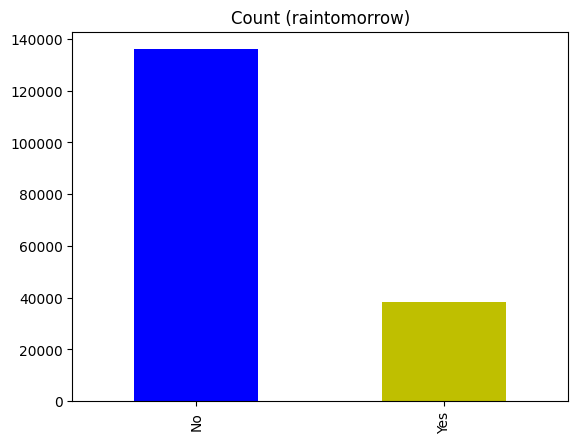

In [29]:
# visualisation de la variable réponse
df_2['raintomorrow'].value_counts().plot(kind='bar', title='Count (raintomorrow)', color=['b', 'y'])

array([[<Axes: title={'center': 'mintemp'}>,
        <Axes: title={'center': 'maxtemp'}>,
        <Axes: title={'center': 'rainfall'}>],
       [<Axes: title={'center': 'windgustspeed'}>,
        <Axes: title={'center': 'windspeed9am'}>,
        <Axes: title={'center': 'windspeed3pm'}>],
       [<Axes: title={'center': 'humidity9am'}>,
        <Axes: title={'center': 'humidity3pm'}>,
        <Axes: title={'center': 'pressure9am'}>],
       [<Axes: title={'center': 'pressure3pm'}>,
        <Axes: title={'center': 'temp9am'}>,
        <Axes: title={'center': 'temp3pm'}>]], dtype=object)

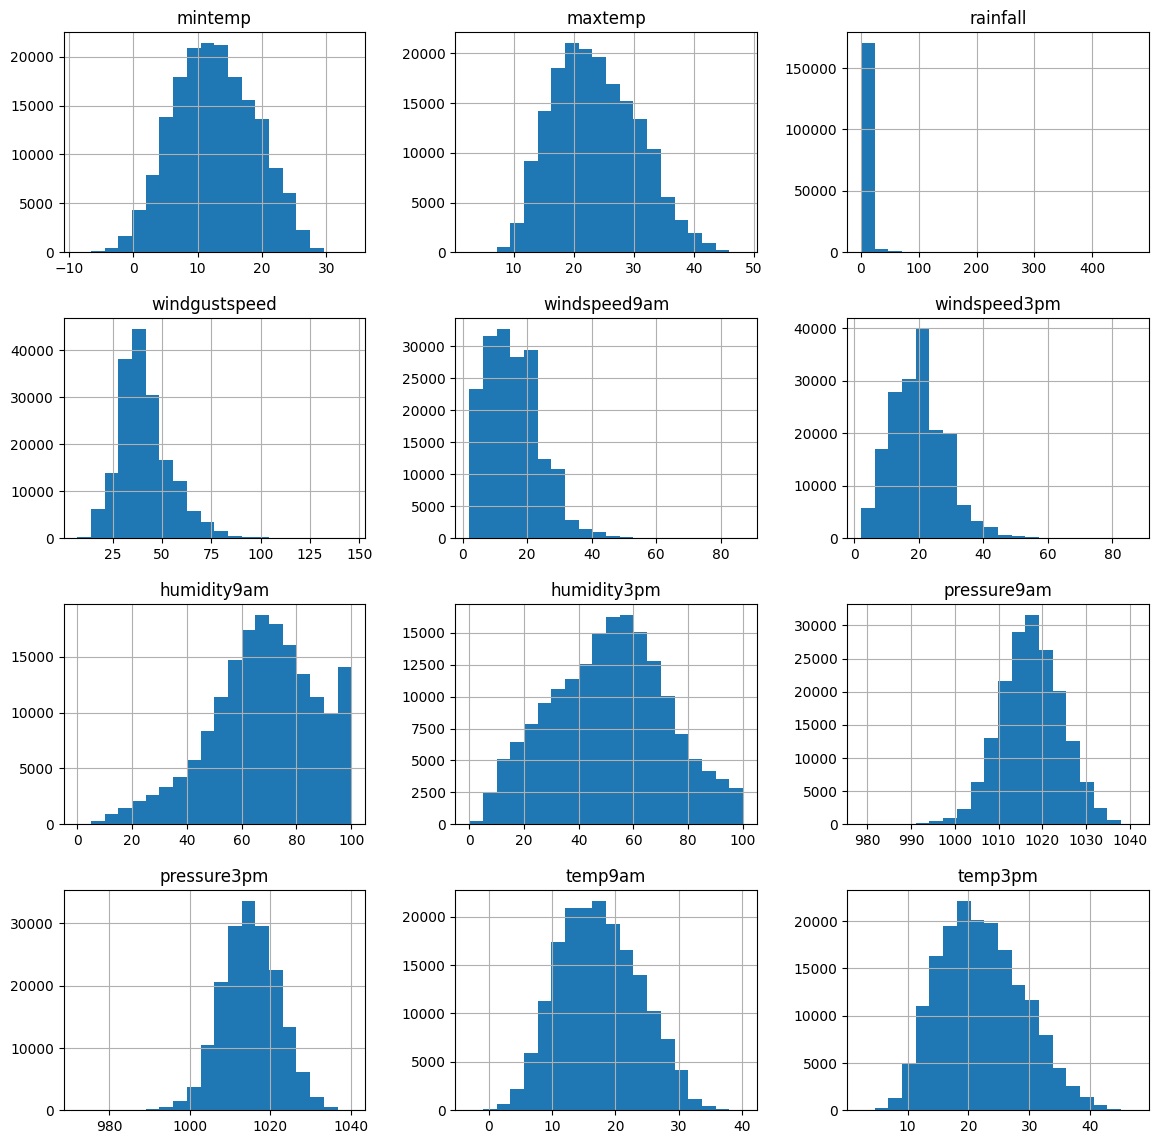

In [30]:
# visualisation des variable prédictives numériques
df_2.hist(bins = 20 , figsize= (14,14))

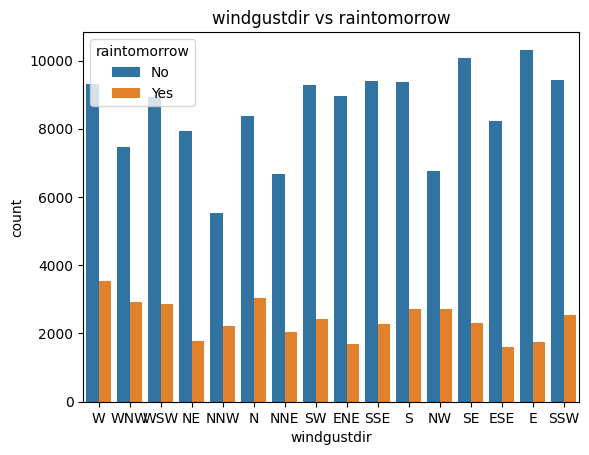

In [31]:
# visualisation d'une variable qualitative versus la variable réponse
sns.countplot(data=df_2, x="windgustdir", hue="raintomorrow")
plt.title('windgustdir vs raintomorrow')
plt.show()

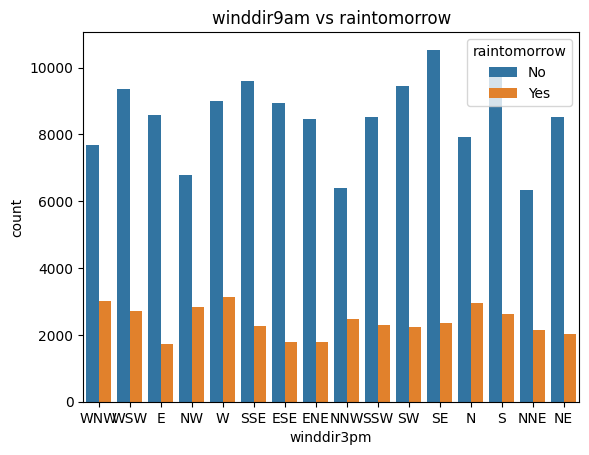

In [32]:
# visualisation d'une variable qualitative versus la variable réponse
sns.countplot(data=df_2, x="winddir3pm", hue="raintomorrow")
plt.title('winddir9am vs raintomorrow')
plt.show()

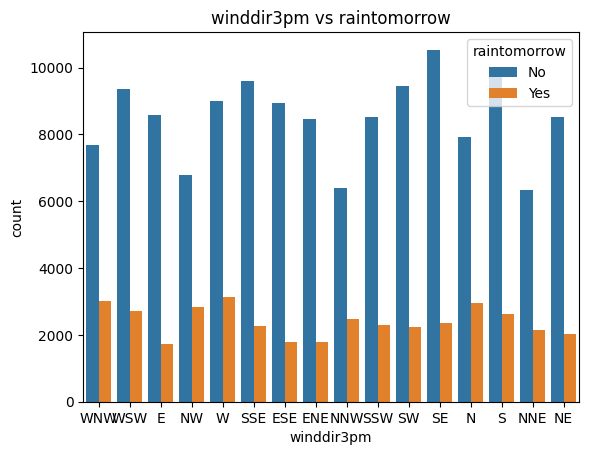

In [33]:
# visualisation d'une variable qualitative versus la variable réponse
sns.countplot(data=df_2, x="winddir3pm", hue="raintomorrow")
plt.title('winddir3pm vs raintomorrow')
plt.show()

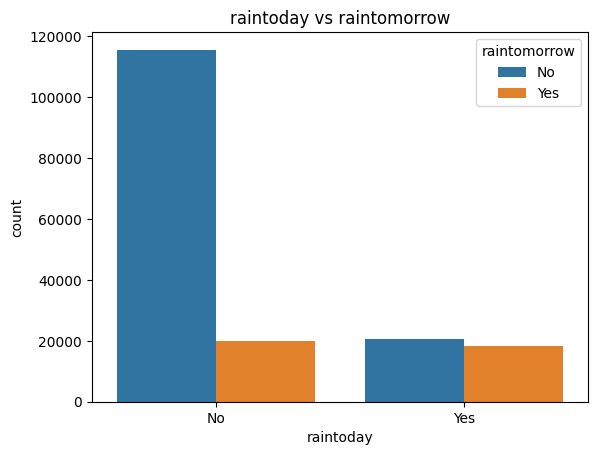

In [34]:
# visualisation d'une variable qualitative versus la variable réponse
sns.countplot(data=df_2, x="raintoday", hue="raintomorrow")
plt.title('raintoday vs raintomorrow')
plt.show()

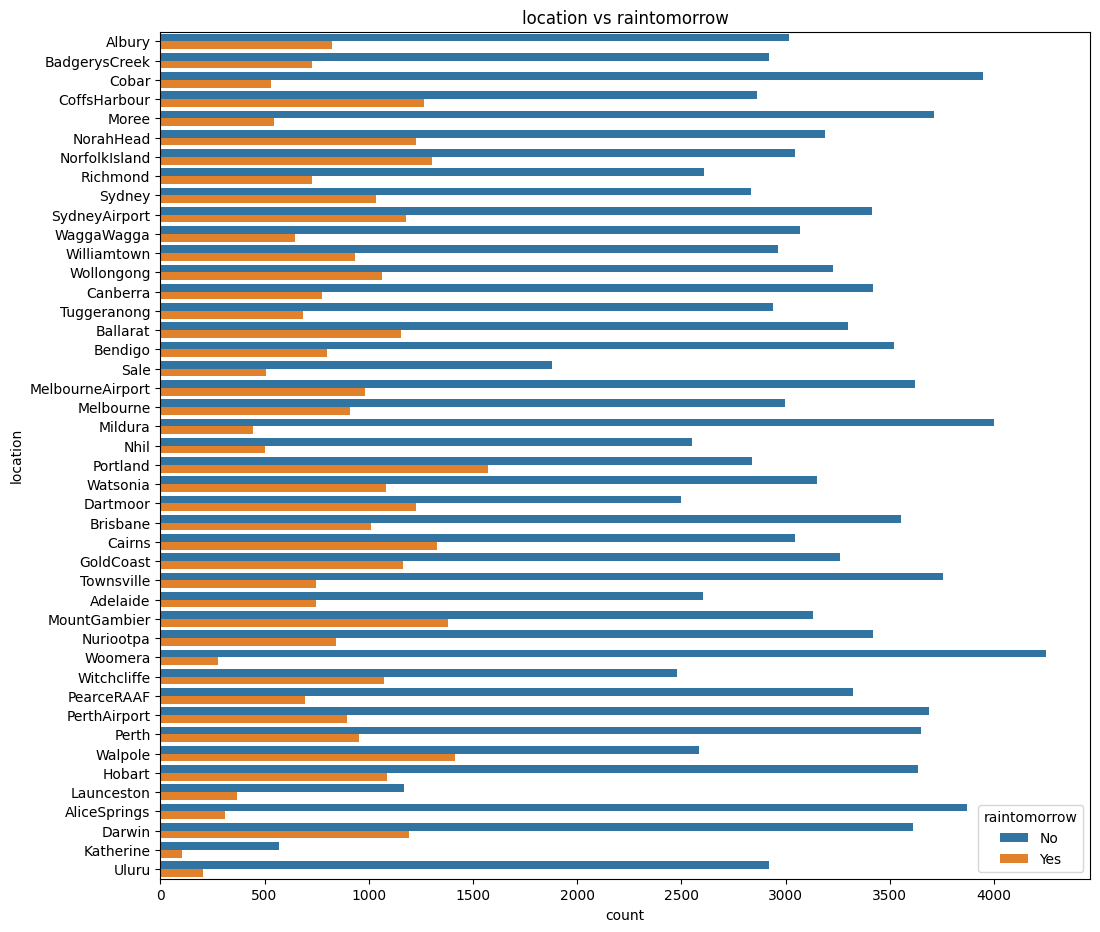

In [35]:
# visualisation d'une variable qualitative versus la variable réponse
plt.figure(figsize=(12,11))

sns.countplot(data=df_2, y="location", hue="raintomorrow")
plt.title('location vs raintomorrow')
plt.show()

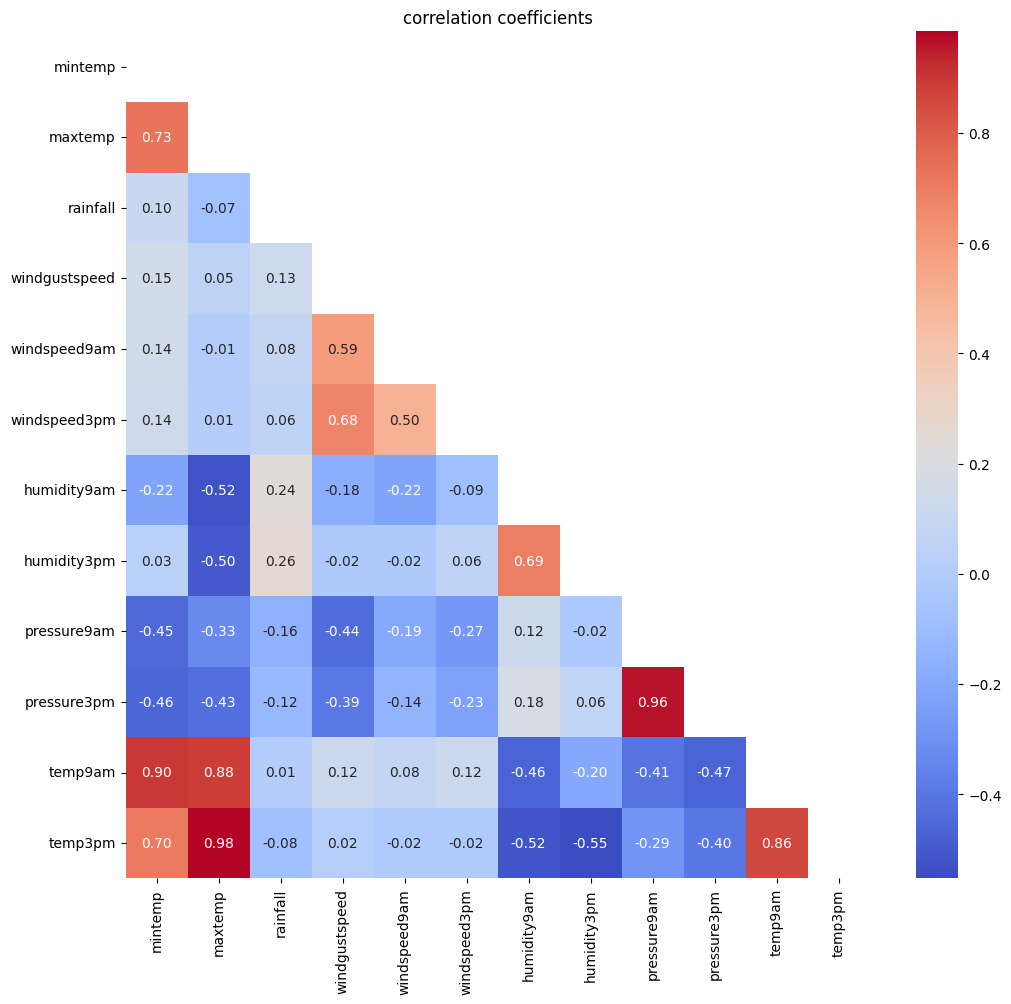

In [36]:
# visaulisation of correlation coefficients
corr = df_2.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
corr = corr.mask(mask)

plt.figure(figsize=(12, 11)) # Set figure size
sns.heatmap(corr, annot=True, cmap='coolwarm',fmt='.2f')
plt.title('correlation coefficients')
plt.show()

In [37]:
# codage disjonctif complet des variables prédictives qualitatives
df_3 = pd.get_dummies(df_2, columns = ['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'])
# codage numérique de la variable réponse
df_3['raintomorrow'].replace({'No':0, 'Yes': 1}, inplace = True)
# visualisation du nouveau dataset encodé
df_3

,mintemp,maxtemp,rainfall,windgustspeed,windspeed9am,windspeed3pm,humidity9am,humidity3pm,pressure9am,pressure3pm,...,winddir3pm_S,winddir3pm_SE,winddir3pm_SSE,winddir3pm_SSW,winddir3pm_SW,winddir3pm_W,winddir3pm_WNW,winddir3pm_WSW,raintoday_No,raintoday_Yes
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-01,13.4,22.9,0.6,44.0,20.0,24.0,71.0,22.0,1007.7,1007.1,...,0,0,0,0,0,0,1,0,1,0
2008-12-02,7.4,25.1,0.0,44.0,4.0,22.0,44.0,25.0,1010.6,1007.8,...,0,0,0,0,0,0,0,1,1,0
2008-12-03,12.9,25.7,0.0,46.0,19.0,26.0,38.0,30.0,1007.6,1008.7,...,0,0,0,0,0,0,0,1,1,0
2008-12-04,9.2,28.0,0.0,24.0,11.0,9.0,45.0,16.0,1017.6,1012.8,...,0,0,0,0,0,0,0,0,1,0
2008-12-05,17.5,32.3,1.0,41.0,7.0,20.0,82.0,33.0,1010.8,1006.0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-03-21,26.5,38.9,0.0,43.0,28.0,11.0,34.0,16.0,1015.2,1011.6,...,0,0,0,0,0,0,0,0,1,0
2023-03-22,25.1,39.1,0.0,39.0,22.0,20.0,28.0,13.0,1014.1,1009.9,...,0,0,0,0,0,0,0,0,1,0
2023-03-23,23.2,39.8,0.0,39.0,20.0,11.0,26.0,12.0,1014.4,1010.4,...,0,0,0,0,0,0,0,0,1,0


In [80]:
# sauvegarde du dataset préparé pour l'apprentissage automatique
#df_3.to_csv('../../datasets/processed/dec2008-march2023/weatherAUS_processed.csv')